# What is the need of numpy array when we have list in Python?

This is bcz the Python's built-in data types are slow in working.<br>
We'll discuss on three topics for Numpy VS list.
1) Speed
2) Memory and
3) Convenience

# 1) Speed: Let's see the speed of list.

In [1]:
import time
import numpy as np

In [2]:
a = [i for i in range(10000000)]
b = [i for i in range(10000000, 20000000)]

print(len(a))

10000000


In [3]:
# Here we will run a loop and calculate time taken.

start_time = time.time()    # This gives the current time
sum_list = []
for i in range(len(a)):
    sum_list.append(a[1] + b[i])
print(f'Time taken to complete the loop: {time.time() - start_time}')

Time taken to complete the loop: 3.523719072341919


In [4]:
time.time()

1729696487.3414295

In [5]:
# On numpy array

a = np.arange(10000000)
b = np.arange(10000000, 20000000)

In [6]:
start_time = time.time()    # This gives the current time

sum_list = a + b    # We don't need loop fo itemwise total in numpy

print(f'Time taken to complete the loop: {time.time() - start_time}')

Time taken to complete the loop: 0.31313490867614746


In [7]:
# The reason why numoy is faster than list is, numpy directly stores the number into the memory,
# whereas list stores the reference.

# 2) Memory: Let's see the memory

In [8]:
import sys

In [9]:
a = [i for i in range(10000000)]
b = np.arange(10000000, dtype = np.int16)    # Default dtype is 'int32'

#  np.arange(10000000, dtype = 'int16')    # 'int16' this way is also valid.

In [10]:
print(sys.getsizeof(a))
print(sys.getsizeof(b))

# We can see There is a high difference in the memory oppucation.

89095160
20000112


# 3) Convenience: Let's see the convenience

In speed's concept, we saw when we were performing itemwise addition, we required loop for list and for numpy, we just wrote **a+b**. This the one of the examples of convenience.

# Indexing:
There're three ways of indexing in numpy. They're
1) **Simple indexing**: We learned in Part: 1
2) **Fancy indexing** and
3) **Boolean indexing**

# 1. Fancy indexing.

In [11]:
a1  = np.arange(8)
a2 = np.arange(24).reshape(6, 4)    # 2-d matrix
a3 = np.arange(24).reshape(2, 3, 4)    # 3-d matrix

In [12]:
for i in a1, a2, a3:
    print(i)
    print()
    print()
    print()

[0 1 2 3 4 5 6 7]



[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]



[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]





In [13]:
# 2-d matrix
a2

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11],
       [12, 13, 14, 15],
       [16, 17, 18, 19],
       [20, 21, 22, 23]])

In [14]:
# Fetch 1st, 3rd and 4th row.
# We cannot do this using simple/normal indexing. Using simple/normal indexing, we can fetch alternate rows/columns
# but not this

# Alternate rows using simple indexing
print(a2[0:4:2])

[[ 0  1  2  3]
 [ 8  9 10 11]]


In [15]:
# Fetch 1st, 3rd and 4th row. Using fancy indexing
# We pass a list while indexing. First list for rows and 2nd list for columns, seperated by comma.

a2[[0, 2, 3]]    # Means i want rows at 0th, 2nd and 3rd position.

array([[ 0,  1,  2,  3],
       [ 8,  9, 10, 11],
       [12, 13, 14, 15]])

In [16]:
# Fetch 1st, 3rd, 4th and 6th row.

a2[[0, 2, 3, 5]]

array([[ 0,  1,  2,  3],
       [ 8,  9, 10, 11],
       [12, 13, 14, 15],
       [20, 21, 22, 23]])

In [17]:
# Fetch 1st, 3rd and 4th column.

a2[:, [0, 2, 3]]

# Fancy indexing is more used with pandas than with numpy

array([[ 0,  2,  3],
       [ 4,  6,  7],
       [ 8, 10, 11],
       [12, 14, 15],
       [16, 18, 19],
       [20, 22, 23]])

In [18]:
# Fetch 1st, 4th and 5th row and 1st, 3rd and 4th column.
# This is not possible by fancy indexing.
# For this, we will have to use np.ix_() method

print(a2)
print()
print()

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]




In [19]:
rows = [0, 3, 4]    # 1st, 4th and 5th row
columns = [0, 2, 3]    # 0th, 2nd and 3rd column

a2[np.ix_(rows, columns)]

array([[ 0,  2,  3],
       [12, 14, 15],
       [16, 18, 19]])

# 2. Boolean indexing.

It is not always that we need to fetch items by position. Sometimes we need to fetch items by condition.<br>
`For ex:`<br>
1. From a given array, fetch all the items divisible by 5<br>
2. Fetch all the even numbers from the array.

In [20]:
a1 = np.random.randint(1, 100, 24).reshape(6, 4)

print(a1)

[[36 87 90 22]
 [50 10 39 49]
 [49 42 55 52]
 [54 12 17 67]
 [81 98 82 38]
 [20  8 78 73]]


In [21]:
# Find all the numbers greater than 50

print(a1>50)   # This gives a boolean array
print()
print()

print(a1[a1>50])   # This will remove all the false items and return a 1-d array of elements>50
print(a1[a1>50].ndim)    # See, it is a 1-d array

[[False  True  True False]
 [False False False False]
 [False False  True  True]
 [ True False False  True]
 [ True  True  True False]
 [False False  True  True]]


[87 90 55 52 54 67 81 98 82 78 73]
1


In [22]:
# Find all the even nos.

print(a1%2 == 0)    # Returns boolean array where True stands for even and False for Odd
print()
print()

print(a1[a1%2 == 0])

[[ True False  True  True]
 [ True  True False False]
 [False  True False  True]
 [ True  True False False]
 [False  True  True  True]
 [ True  True  True False]]


[36 90 22 50 10 42 52 54 12 98 82 38 20  8 78]


In [23]:
# Find all the nos greater than 50 and are even

print((a1>50) & (a1%2 == 0))    # Returns a boolean array of >50 and is even
# We used & here bcz it is a bitwise operator and when we deal with bool, we use bitwise operator
# We use 'and' when dealing with if/else and loops bcz it is a logical operator

print()
print()

print(a1[(a1>50) & (a1%2 == 0)])

[[False False  True False]
 [False False False False]
 [False False False  True]
 [ True False False False]
 [False  True  True False]
 [False False  True False]]


[90 52 54 98 82 78]


In [24]:
# Find all the numbers that are not divisible by 7

print(a1%7 != 0)
print()
print()

print(a1[a1%7 != 0])
print()

print(a1[~(a1%7 == 0)])    # We can also use not operator as well

[[ True  True  True  True]
 [ True  True  True False]
 [False False  True  True]
 [ True  True  True  True]
 [ True False  True  True]
 [ True  True  True  True]]


[36 87 90 22 50 10 39 55 52 54 12 17 67 81 82 38 20  8 78 73]

[36 87 90 22 50 10 39 55 52 54 12 17 67 81 82 38 20  8 78 73]


In [25]:
a1[~(a1%7 == 0)]

array([36, 87, 90, 22, 50, 10, 39, 55, 52, 54, 12, 17, 67, 81, 82, 38, 20,
        8, 78, 73])

# Brodcasting.

The term broadcasting describes how NumPy treats arrays with different shapes during arithmetic operations.<br>

The smaller array is “broadcast” across the larger array so that they have compatible shapes.

In [26]:
# Arrays of same shapes.

a1 = np.arange(6).reshape((2, 3))
a2 = np.arange(6, 12).reshape((2, 3))

print(a1)
print()
print()

print(a2)

[[0 1 2]
 [3 4 5]]


[[ 6  7  8]
 [ 9 10 11]]


In [27]:
a1+a2

# Obv, it will work. But now see arrays of different shapes.

array([[ 6,  8, 10],
       [12, 14, 16]])

In [28]:
# Different shape.

a1 = np.arange(6).reshape((2, 3))
a2 = np.arange(3).reshape((1, 3))

print(a1)
print()
print()

print(a2)

# We know that atithmetic operation on arrays is possible only if both the metrices have same no_of rows and columns
# Here size of 1st metrix is (2, 3) and 2nd metrix is (1,3). So addition or substraction is not possible

# But let's see what happen if we add these two metrices.

[[0 1 2]
 [3 4 5]]


[[0 1 2]]


In [29]:
# Applying addition

a1+a2

array([[0, 2, 4],
       [3, 5, 7]])

This worked. But how? This is what Brodcasting is. The reason is Broadcasting.

Understand the working properly.

What it does is, Consider our example. We were having 2 metrix with shape (2, 3) and (1, 3).
We have only one row in smaller metrix. So converts it into 3 rows.
In all the three rows, the numbers are same.
For eg: The (0, 1, 2), size(1, 3) becomes <br>
[[0 1 2]<br>
[0 1 2]<br>
[0 1 2]]<br>
of shape(3, 3) and now the addition is possible, acc. to the rule.
                                          
The same happens when columns are of different shape

See the below image for better understanding (For our scenerio, see the 2nd point of the image).

<img src = "https://jakevdp.github.io/PythonDataScienceHandbook/figures/02.05-broadcasting.png">


# Rules of `Broadcasting`:
1) If the numbers of dimensions of the two arrays are different, add new dimensions with size 1 to the head of the array with the smaller dimension.
2) If the sizes of each dimension of the two arrays do not match, dimensions with size 1 are stretched to the size of the other array.
3) If there is a dimension whose size is not 1 in either of the two arrays, it cannot be broadcasted, and an error is raised.
# First scenerio.



**A** = [[1, 2, 3],<br>
[4, 5, 6],<br>
[7, 8, 9]] size(3, 3), dimension: 2-d<br>

**B** = [1, 2, 3], size = (3,)(`Means 3 elments`), dimension: 1-d.Here dimension of both the arrays, A and B, are different, 2-d and 1-d respectively.<br>
So acc. to rule 1, **add new dimensions with size 1 to the head of the array with the smaller dimension.**<br>
Here array with smaller dimension is **B(dimension: 1, size: (3,))** So 1 will be added to the head of its size.<br>
Hence, now `new_size = (1, 3)` and it becomes a 2-d array.<br>

Now when both A and B has same dimensions i.e 2-d, see the second rule. It says that `If the sizes of each dimension of the two arrays do not match, dimensions with size 1 are stretched to the size of the other array.`<br>
If the size of two same dimensions do not match, the dimension with size 1 is stretched to the size of other array.<br>
Here dimension with size 1 is array `B(new_size: (1, 3)`<br>
So acc. to rule, 1 is stretched to the size of other array i.e size of array `A i.e 3`. So 1 is streatched to 3<br>
So now, the new_size of array **B** becomes **(3,3)** which is same as size of array **A** i.e **(3,3)**.
Hence now, addition or substraction is possible between A and B.

# Note: If condition 1 is already satisfied, directly move to condition 2.

# Condition 3.

See this array
A = np.array([[1, 2], [3, 4]])  # Shape: (2, 2)<br>
B = np.array([5, 6, 7])         # Shape: (3,)<br>

C = A + B  # Raises a ValueError<br>

If we add 1 on the head of B and streatched it to 2, it becomes (1, 3). Addition/ Substraction is not possible.<br>
This is what condition 3 says.

# Remember, Regardless of the position of 1 at(rows position or columns position), it is streatched to met the size of the other array.
For eg. 
1) <br>
`Size of A: (3, 3)`<br>
`Size of B: (3, 1)`<br>
**1 in B will be stretched to coresponding 3 of A**
<br>


2) `Size of A: (4, 3)`<br>
`Size of B: (1, 3)`<br>
**1 in B will be stretched to coresponding 4 of A**

<br>

3) `Size of A: (1, 4)`<br>
`Size of B: (4, 1)`<br>
**1 of A will be streatched to coresponding 4 of B and<br>
1 of B will be streatched to coresponding 4 of A**
w 

# Examples for all the three conditions.

**Condition: 1**

A = np.array([[1, 2], [3, 4]])  # Shape: (2, 2)<br>
B = np.array([5, 6])           # Shape: (2,)<br>

C = A + B  # Broadcasting works here<br>
In this case, **B** is broadcasted to a (2, 2) shape by repeating its values along the second dimension. The resulting **C** is:<br>
[[6, 8]<br>
[8, 10]]

**Condition: 2**

A = np.array([[1, 2], [3, 4]])  # Shape: ( r> <br>2)
B = np.array([[5, 6], [7, 8]])    # Shape: r> <br> 2)

C = A + B  # Broadcasting works.`Here, both arrays have the same shape, so broadcasting is straightforward.`

**Condition: 3**

A = np.array([[1, 2], [3, 4]])  # Shape: (2, 2)<br>
B = np.array([5, 6, 7])         # Shape: (3,)<br>

C = A + B  # Raises a ValueError

In this case, the first dimension of **A** is 2, while the first dimension of **B** is 3. Since both dimensions have sizes greater than 1 and they don't match, broadcasting is not possible.<br>

**Inshort, increment depends on 1, if it finds number greater than 1, error is raised.**

# `Remember`: Broadcasting is a flexible mechanism that can simplify many array operations, but it's essential to understand the rules to avoid unexpected errors. here

In [30]:
# More examples
a = np.arange(12).reshape(4,3)
b = np.arange(3)

print(a)
print()
print()

print(b)
print()
print()

# Broadcasting is possible.

print(a + b)

[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


[0 1 2]


[[ 0  2  4]
 [ 3  5  7]
 [ 6  8 10]
 [ 9 11 13]]


In [31]:
# Question: 2

a = np.arange(12).reshape((3, 4))    # 2-d array
b = np.arange(3)

print(a)
print()
print()

print(b)
print()
print()

# Remember rule no 3. See the shapes,
print(a.shape)
print(b.shape)
print()
print()

# So acc. to rule no 3, broadcasting is not possible
print(a + b)    # Error

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]


[0 1 2]


(3, 4)
(3,)




ValueError: operands could not be broadcast together with shapes (3,4) (3,) 

In [32]:
# Question: 3

a = np.arange(3).reshape((1, 3))
b = np.arange(3).reshape((3, 1))

print(a)
print()
print()

print(b)
print()
print()

# Broadcasting is possible.

print(a + b)

[[0 1 2]]


[[0]
 [1]
 [2]]


[[0 1 2]
 [1 2 3]
 [2 3 4]]


In [33]:
# Questio: 4

a = np.arange(3).reshape((1, 3))
b = np.arange(4).reshape(4, 1)

print(a)
print()
print()

print(b)
print()
print()

# Broadcasting is possible.

print(a + b)

[[0 1 2]]


[[0]
 [1]
 [2]
 [3]]


[[0 1 2]
 [1 2 3]
 [2 3 4]
 [3 4 5]]


In [34]:
# Question: 5

a = np.array([2])
b = np.arange(4).reshape(2, 2)

print(a)
print()
print()

print(b)
print()
print()

# Broadcasting is possible.

print(a + b)

[2]


[[0 1]
 [2 3]]


[[2 3]
 [4 5]]


In [35]:
# Question: 6

a = np.arange(12).reshape((4, 3))
b = np.arange(12).reshape((3, 4))

print(a)
print()
print()

print(b)
print()
print()

# Broadcasting is not possible.

print(a + b)    # Error. Bcz there is no 1 anywhere

[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]




ValueError: operands could not be broadcast together with shapes (4,3) (3,4) 

In [36]:
# Question: 7

a = np.arange(16).reshape((4, 4))
b = np.arange(4).reshape((2, 2))

print(a)
print()
print()

print(b)
print()
print()

# Broadcasting is not possible.

print(a + b)    # Error. Bcz there is no 1 anywhere

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]


[[0 1]
 [2 3]]




ValueError: operands could not be broadcast together with shapes (4,4) (2,2) 

# Working with mathematical formulae.
1) Sigmoid
2) Mean Squared Error
3) Binary Cross Entropy

We know we have some built-in function in numpy, like, sum(), sin(), where(), mean(), median(), mode(), min(), max() etc...<br>
But what if we want to apply some other functions. We can do this as well by creating our own `UDF` and apply it to an numpy array.

In [37]:
# 1) Sigmoid of an array.
# Formula: S(x) = 1 / (1+e**(-x))
# One divided by (1 + e raised to -x)

a = np.arange(1, 100)
a

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85,
       86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])

In [38]:
def sigmoid(arr):
    return 1 / (1+ (np.exp(-(arr))))

In [39]:
sigmoid(a)

# Sigmoid should be between 0 and 1 and we are also getting the same results

array([0.73105858, 0.88079708, 0.95257413, 0.98201379, 0.99330715,
       0.99752738, 0.99908895, 0.99966465, 0.99987661, 0.9999546 ,
       0.9999833 , 0.99999386, 0.99999774, 0.99999917, 0.99999969,
       0.99999989, 0.99999996, 0.99999998, 0.99999999, 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.     

In [40]:
# Mean Squared Error:

# Formula:
# MSE = Sum of (actual - predicted)**2) / total no_of items

def mse(actual, predicted):
    return np.mean((actual - predicted)**2)

In [41]:
actual = np.random.randint(1, 50, 25)
predicted = np.random.randint(1, 50, 25)

In [42]:
mse(actual, predicted)

480.36

In [43]:
np.mean((actual-predicted)**2)

480.36

In [44]:
# 3) BInary Cross Entropy

# Try yourself

# Working with missing values.

**np.nan** and **None** bith are different. **None** is not a missing value. Python treats **np.nan** as missing values and not **None**

In [45]:
a = np.array([1, 2, 3, 4, 5, np.nan, 7, 8])
a

array([ 1.,  2.,  3.,  4.,  5., nan,  7.,  8.])

In [46]:
# Fetch non missing values

np.isnan(a)    # Returns True and false for non-missing and missing respectively.

array([False, False, False, False, False,  True, False, False])

In [47]:
a[np.isnan(a)]    # Retruns missing values. But we wnat non missing values.

array([nan])

In [48]:
a[~np.isnan(a)]

array([1., 2., 3., 4., 5., 7., 8.])

~ stand for making the statement reverse. means if the code is returning missing values,
adding ~ before the code will return non-missing values.

It actually convers 'True' to 'False' and vice-versa and then the code np.isnan() returns True values.
We will use this concept in our later topics of Pandas.

# Plotting graphs

In [49]:
x = np.linspace(-10, 10, 100)    # Returns values ranging from -10 to 10 at equal distance
y = x

In [1]:
import matplotlib.pyplot as plt

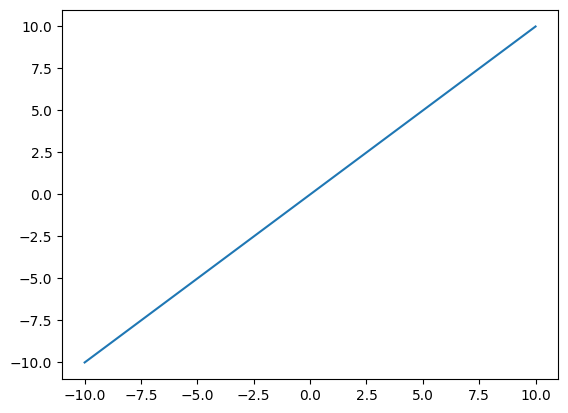

In [51]:
plt.plot(x, y)    # size of x and y should be same

In [52]:
# 2nd example

x = np.linspace(-10, 10, 100)    # Returns values ranging from -10 to 10 at equal distance
y = x ** 2

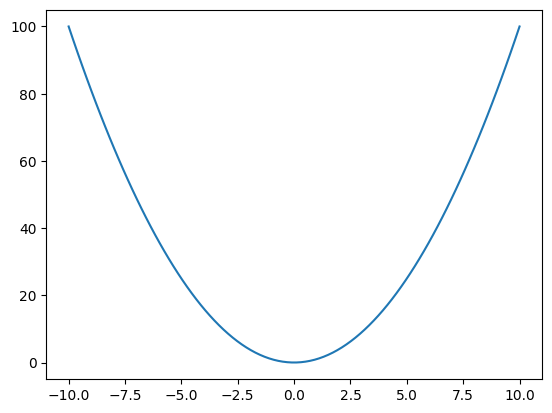

In [53]:
plt.plot(x, y)

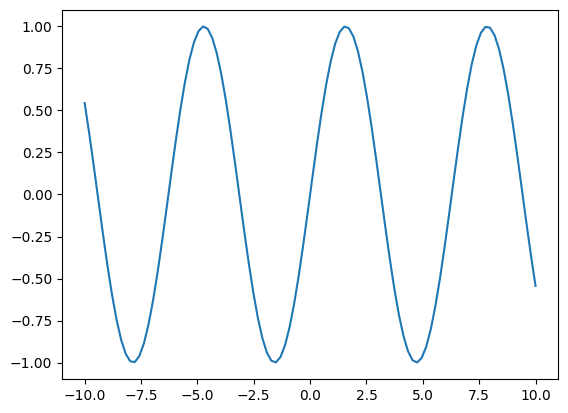

In [54]:
# 3rd example. y = sin(x)

x = np.linspace(-10, 10, 100)
y = np.sin(x)

plt.plot(x, y)

C:\Users\jugal\AppData\Local\Temp\ipykernel_12020\1520333261.py:4: RuntimeWarning: invalid value encountered in log
  y = x * (np.log(x))


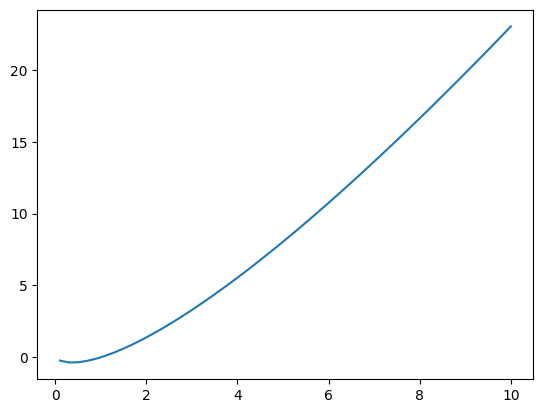

In [55]:
# 4th example. y = xlog(x)

x = np.linspace(-10, 10, 100)
y = x * (np.log(x))

plt.plot(x, y)

In [56]:
# 4th example. y = exp(x)

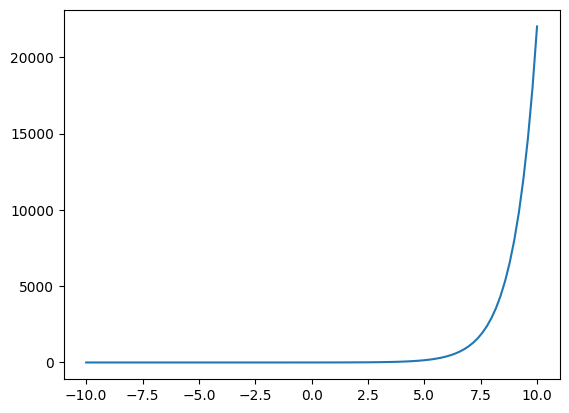

In [57]:
x = np.linspace(-10, 10, 100)
y = np.exp(x)

plt.plot(x, y)

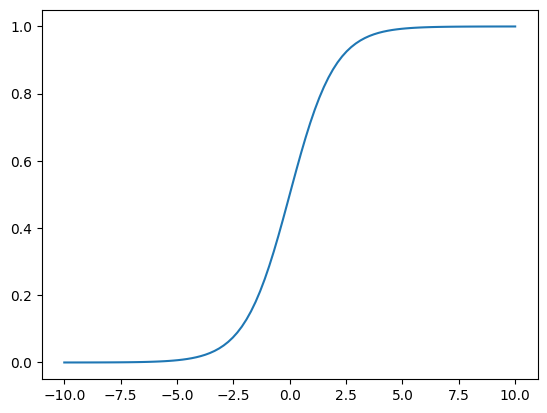

In [58]:
# 5th example. Sigmoid

x = np.linspace(-10, 10, 100)
y = 1/ (1 + np.exp(-x))

plt.plot(x, y)

# Completed. Next session: Numpy tricks